In [16]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math

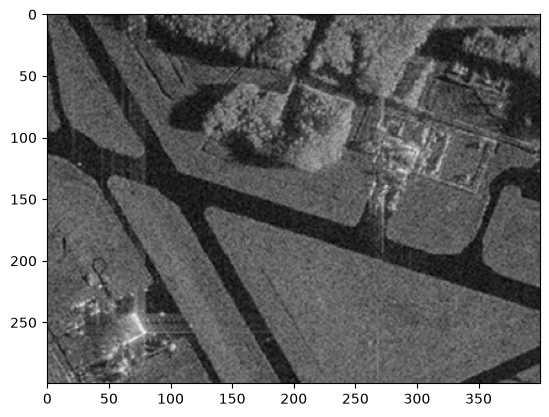

In [17]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

# Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [18]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])

    if abs(av_val - img[point]) <= T:
        return True

    return False

In [19]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r + 1, j-r: j+r+1].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        #print(count)
        mask += local_mask

    return mask*255

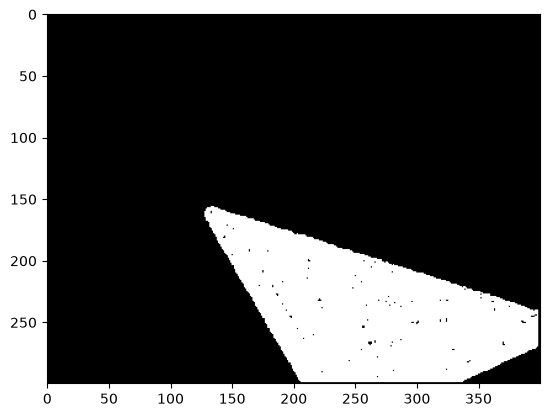

In [20]:
seed_point = (200,225)
mask = region_growing(image_gray,seed_point,homo_average,1, 25)
plt.imshow(mask, cmap="gray")

Подобрав точку (200, 225) и порог T = 25, удалось выделить газон

# Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

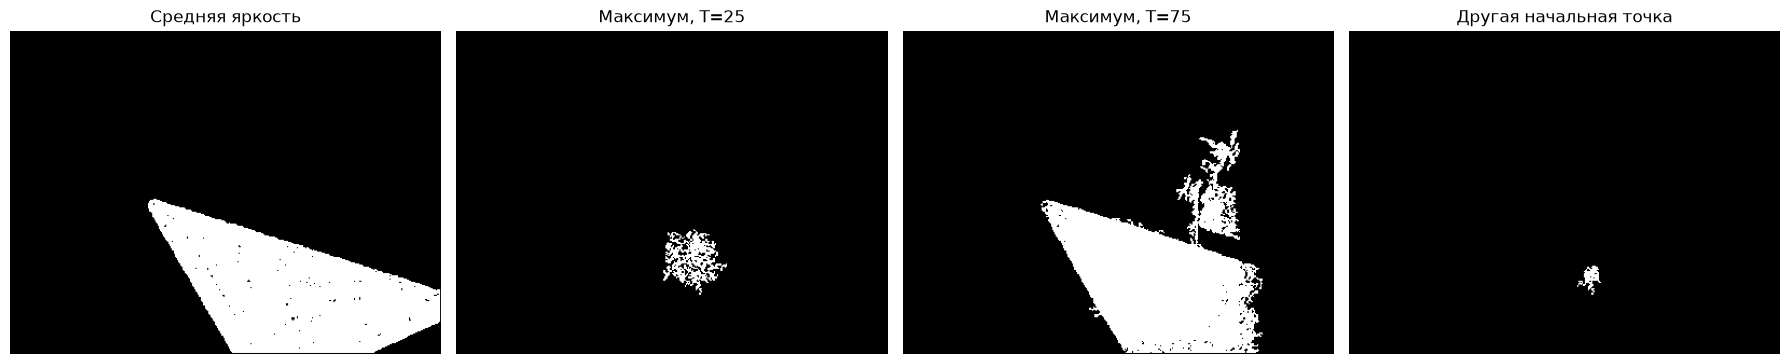

In [21]:
def homo_max(img, mask, point, threshold):
    max_value = np.max(img[mask != 0])
    return abs(float(max_value) - float(img[point])) <= threshold


mask_max_25 = region_growing(image_gray, (200, 225), homo_max, 1, 25)
mask_max_75 = region_growing(image_gray, (200, 225), homo_max, 1, 75)
mask_max_other_seed = region_growing(image_gray, (225, 225), homo_max, 1, 25)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
results = [mask, mask_max_25, mask_max_75, mask_max_other_seed]
titles = ['Средняя яркость', 'Максимум, T=25', 'Максимум, T=75', 'Другая начальная точка']
for ax, result, title in zip(axes, results, titles):
    ax.imshow(result, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()

Dычисление разницы между средней яркостью и яркостью в точке в качестве критерия работает лучше, чем разница между максимумом и яркостью в точке

# Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

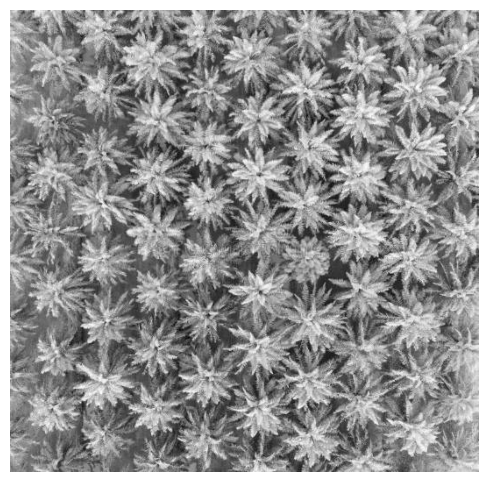

In [22]:
palm_image = cv2.imread('palm_1.jpg')
palm_gray = cv2.cvtColor(palm_image, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(9, 6))
plt.imshow(palm_gray, cmap='gray')
plt.axis('off');

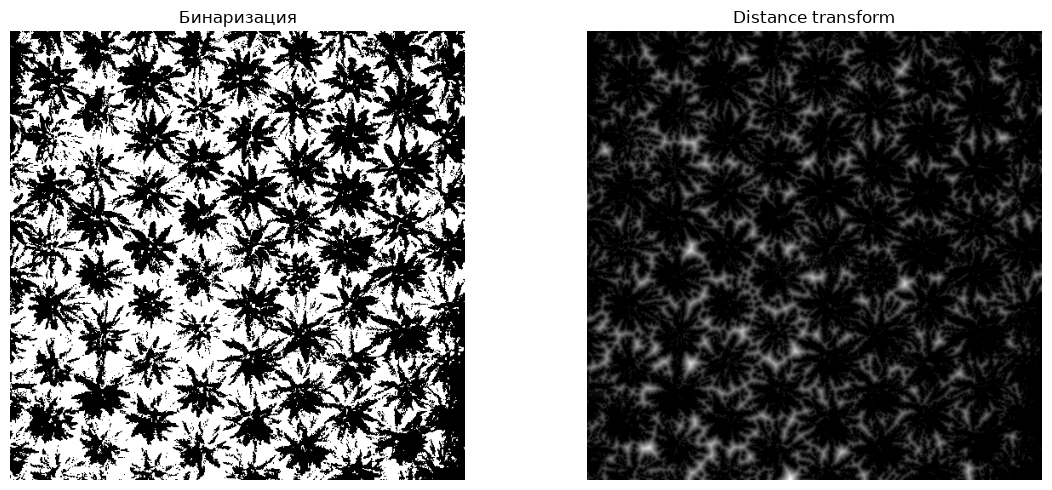

In [23]:
_, binary = cv2.threshold(
    palm_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
distance = cv2.distanceTransform(binary, cv2.DIST_L2, 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(binary, cmap='gray'); axes[0].set_title('Бинаризация')
axes[1].imshow(distance, cmap='gray'); axes[1].set_title('Distance transform')
for ax in axes:
    ax.axis('off')
plt.tight_layout()

In [24]:
target_count = 69
coefficients = np.arange(0.05, 0.71, 0.05)
best_error = float('inf')
best_coefficient = None
best_count = 0
counts = []

for coefficient in coefficients:
    _, foreground = cv2.threshold(
        distance, coefficient * distance.max(), 255, cv2.THRESH_BINARY
    )
    foreground = foreground.astype(np.uint8)
    _, markers = cv2.connectedComponents(foreground)
    markers = cv2.watershed(palm_image.copy(), markers.astype(np.int32))
    tree_count = len(np.unique(markers[markers > 0]))
    counts.append(tree_count)

    error = abs(tree_count - target_count)
    if error < best_error:
        best_error = error
        best_coefficient = coefficient
        best_count = tree_count

    print(f'Коэффициент: {coefficient:.2f}, областей: {tree_count}')

print(f'\nЛучший коэффициент: {best_coefficient:.2f}')
print(f'Количество выделенных деревьев: {best_count}')

Коэффициент: 0.05, областей: 1218
Коэффициент: 0.10, областей: 739
Коэффициент: 0.15, областей: 624
Коэффициент: 0.20, областей: 524
Коэффициент: 0.25, областей: 435
Коэффициент: 0.30, областей: 397
Коэффициент: 0.35, областей: 292
Коэффициент: 0.40, областей: 223
Коэффициент: 0.45, областей: 160
Коэффициент: 0.50, областей: 111
Коэффициент: 0.55, областей: 65
Коэффициент: 0.60, областей: 45
Коэффициент: 0.65, областей: 22
Коэффициент: 0.70, областей: 12

Лучший коэффициент: 0.55
Количество выделенных деревьев: 65


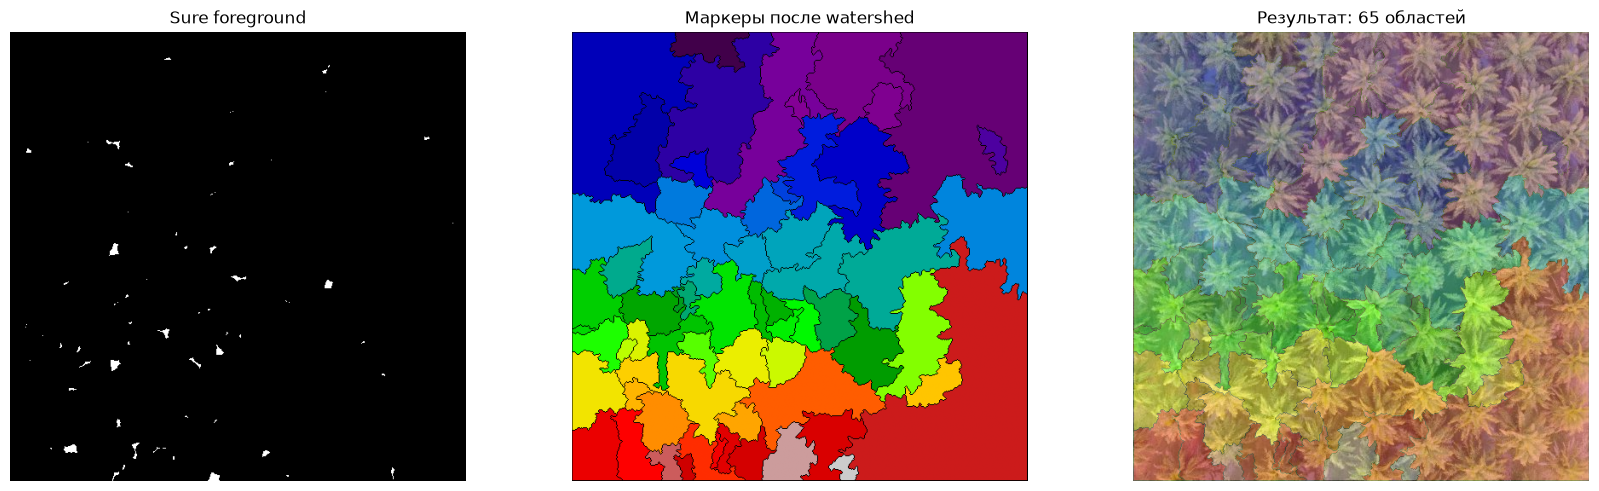

In [25]:
_, foreground = cv2.threshold(
    distance, best_coefficient * distance.max(), 255, cv2.THRESH_BINARY
)
foreground = foreground.astype(np.uint8)
_, markers = cv2.connectedComponents(foreground)
markers = cv2.watershed(palm_image.copy(), markers.astype(np.int32))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].imshow(foreground, cmap='gray')
axes[0].set_title('Sure foreground')
axes[1].imshow(markers, cmap='nipy_spectral')
axes[1].set_title('Маркеры после watershed')
axes[2].imshow(cv2.cvtColor(palm_image, cv2.COLOR_BGR2RGB))
axes[2].imshow(markers, cmap='nipy_spectral', alpha=0.35)
axes[2].set_title(f'Результат: {best_count} областей')
for ax in axes:
    ax.axis('off')
plt.tight_layout()

Алгоритм сегментации watershed позволяет разделять изображение на отдельные области по структуре градиентов. Применение дистанционного преобразования и предварительной обработки помогает уменьшить проблему чрезмерной сегментации.